# Unfolding scaling-sweep analysis

Analyzes the trial CSVs written by `run_scaling_sweep.py` / the ad-hoc
`compare_methods(...)` runs (`scaling_sweep_data/*_trials.csv`).

**Central question:** does `steepest_edge` ever produce a genuine overlap, as
n (number of faces) grows?

**Real vs. noise, in one paragraph:** the circle packing itself is only
accurate to within `packing_residual` (its own circles are tangent up to
that much floating-point error). A pair's unfolded distance dipping below
1.0 by less than that same residual is indistinguishable from that baseline
noise. The pipeline's own rule of thumb ("certified") requires a deficit
more than 10x the residual before trusting it as real -- but that threshold
is a judgment call, not a law of nature. This notebook shows **both** the
certified (filtered) view **and** the complete raw/unfiltered data, so you
can apply your own threshold instead of trusting the pipeline's.

Re-run this notebook top to bottom any time after generating more sweep
data -- everything here recomputes from the CSVs in `scaling_sweep_data/`,
nothing is hardcoded.


In [1]:
import glob
import math
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

DATA_DIR = Path("scaling_sweep_data")

METHOD_COLORS = {
    "steepest_edge": "#1b6ca8",
    "dfs": "#d9534f",
    "bfs": "#5cb85c",
    "shortest_paths": "#8e44ad",
    "min_degree_shortest_paths": "#e67e22",
    "max_degree_shortest_paths": "#16a085",
}


## Load all trial data

Pulls in every `*_trials.csv` under `scaling_sweep_data/` that has the
post-audit schema (i.e. includes `num_overlappings_certified` -- older,
pre-audit CSVs are skipped since they can't distinguish certified from raw
and aren't comparable to this pipeline's tolerance).


In [2]:
csv_paths = sorted(glob.glob(str(DATA_DIR / "*_trials.csv")))
frames = []
for path in csv_paths:
    df = pd.read_csv(path)
    if "num_overlappings_certified" not in df.columns:
        print(f"(skipping {path}: pre-audit CSV, no certified-overlap column)")
        continue
    frames.append(df)

df_trials = pd.concat(frames, ignore_index=True)

# Derived columns used throughout.
df_trials["margin"] = df_trials["min_plane"] - 1.0          # >0 = no overlap, <0 = raw dip below touching
df_trials["deficit"] = -df_trials["margin"]                  # >0 = how far below touching
df_trials["ratio_deficit_to_residual"] = df_trials["deficit"] / df_trials["packing_residual"]
df_trials["is_certified"] = df_trials["num_overlappings_certified"] > 0
df_trials["has_raw_overlap"] = df_trials["num_overlappings"] > 0

print(f"Loaded {len(df_trials)} (trial, method) rows from {len(frames)} CSV file(s).")
df_trials.head()


Loaded 900 (trial, method) rows from 3 CSV file(s).


,run_id,run_timestamp,root_seed,trial_seed,trial,method,n_points,pairs,min_plane,min_sphere,...,median_delta,viol_plane_lt_sphere,num_overlappings,num_overlappings_certified,packing_residual,margin,deficit,ratio_deficit_to_residual,is_certified,has_raw_overlap
0,quick_n1500,2026-09-23T13:33:52,1790184832759178000,6413397404940542553,1,steepest_edge,1500,1122751,1.00005,1,...,675.134,14,0,0,5.16496e-07,4.9489e-05,-4.9489e-05,-95.8168,False,False
1,quick_n1500,2026-09-23T13:33:52,1790184832759178000,6413397404940542553,1,dfs,1500,1122751,-1.03607,1,...,5237.21,3320,26,26,5.16496e-07,-2.03607,2.03607,3.94208e+06,True,True
2,quick_n1500,2026-09-23T13:33:52,1790184832759178000,6413397404940542553,1,bfs,1500,1122751,0.802634,1,...,727.891,161,8,8,5.16496e-07,-0.197366,0.197366,382124,True,True
3,quick_n1500,2026-09-23T13:33:52,1790184832759178000,8959654010396178345,2,steepest_edge,1500,1122751,0.999979,0.999992,...,666.767,14,1,0,6.01122e-05,-2.08645e-05,2.08645e-05,0.347093,False,True
4,quick_n1500,2026-09-23T13:33:52,1790184832759178000,8959654010396178345,2,dfs,1500,1122751,-0.508938,0.999992,...,4916.6,10912,19,19,6.01122e-05,-1.50894,1.50894,25102,True,True


## 1. Certified-only summary table (filtered)

One row per (n, method). Only counts overlaps that cleared the 10x
packing-residual safety factor -- this is the pipeline's own "trust this"
view.


In [3]:
def summarize(df, overlap_count_col):
    g = df.groupby(["n_points", "method"], as_index=False)
    out = g.agg(
        trials=("trial", "count"),
        pct_trials_with_overlap=(overlap_count_col, lambda s: 100.0 * (s > 0).mean()),
        total_overlaps=(overlap_count_col, "sum"),
        worst_deficit=("deficit", lambda s: s[df.loc[s.index, overlap_count_col] > 0].max()
                       if (df.loc[s.index, overlap_count_col] > 0).any() else float("nan")),
        avg_min_plane=("min_plane", "mean"),
        avg_packing_residual=("packing_residual", "mean"),
        worst_packing_residual=("packing_residual", "max"),
    )
    return out.sort_values(["method", "n_points"]).reset_index(drop=True)

certified_summary = summarize(df_trials, "num_overlappings_certified")
certified_summary


,n_points,method,trials,pct_trials_with_overlap,total_overlaps,worst_deficit,avg_min_plane,avg_packing_residual,worst_packing_residual
0,800,bfs,50,64,53,0.886578,0.901429,1.01612e-06,1.29478e-05
1,1500,bfs,100,100,388,1.88396,0.716978,7.1489e-06,8.58157e-05
2,2000,bfs,150,100,972,1.90302,0.648745,2.1792e-05,0.0014623
3,800,dfs,50,100,948,12.7671,-1.57234,1.01612e-06,1.29478e-05
4,1500,dfs,100,100,5560,21.1672,-2.7977,7.1489e-06,8.58157e-05
5,2000,dfs,150,100,13905,111.693,-3.92827,2.1792e-05,0.0014623
6,800,steepest_edge,50,0,0,NaN,1.00011,1.01612e-06,1.29478e-05
7,1500,steepest_edge,100,0,0,NaN,1.00003,7.1489e-06,8.58157e-05
8,2000,steepest_edge,150,0,0,NaN,1.00001,2.1792e-05,0.0014623


## 2. RAW / unfiltered summary table -- every detected dip, no noise filtering

Same shape as above, but counts **every** trial where `min_plane < 1`
(`num_overlappings`, the raw geometric test), regardless of whether it
cleared the certification threshold. This is the number before any
noise judgment is applied -- use it to decide for yourself where you'd
draw the line.


In [4]:
raw_summary = summarize(df_trials, "num_overlappings")
raw_summary


,n_points,method,trials,pct_trials_with_overlap,total_overlaps,worst_deficit,avg_min_plane,avg_packing_residual,worst_packing_residual
0,800,bfs,50,64,53,0.886578,0.901429,1.01612e-06,1.29478e-05
1,1500,bfs,100,100,390,1.88396,0.716978,7.1489e-06,8.58157e-05
2,2000,bfs,150,100,990,1.90302,0.648745,2.1792e-05,0.0014623
3,800,dfs,50,100,948,12.7671,-1.57234,1.01612e-06,1.29478e-05
4,1500,dfs,100,100,5566,21.1672,-2.7977,7.1489e-06,8.58157e-05
5,2000,dfs,150,100,13935,111.693,-3.92827,2.1792e-05,0.0014623
6,800,steepest_edge,50,0,0,NaN,1.00011,1.01612e-06,1.29478e-05
7,1500,steepest_edge,100,3,3,3.60371e-05,1.00003,7.1489e-06,8.58157e-05
8,2000,steepest_edge,150,10,24,0.000433831,1.00001,2.1792e-05,0.0014623


## 3. Full raw per-trial detail -- every single trial, nothing hidden

Every trial where a raw dip below touching occurred (`num_overlappings > 0`),
for every method and n. Sorted by `ratio_deficit_to_residual` ascending, so
the most noise-like cases (ratio near or below 1x) are at the top and the
most obviously-real cases (large ratio) are at the bottom.

`is_certified` is just a label from the pipeline's 10x rule -- it does not
filter this table. Every row here is real, raw data.

The full trial-by-trial table (including trials with zero overlaps) is also
available as the `df_trials` DataFrame above if you want to slice it
yourself, e.g. `df_trials[df_trials.method == "steepest_edge"]`.


In [5]:
detail_cols = ["n_points", "method", "trial", "trial_seed", "num_overlappings",
               "num_overlappings_certified", "is_certified", "min_plane", "deficit",
               "packing_residual", "ratio_deficit_to_residual"]

raw_detail = (df_trials[df_trials["has_raw_overlap"]][detail_cols]
              .sort_values("ratio_deficit_to_residual")
              .reset_index(drop=True))

print(f"{len(raw_detail)} trials had at least one raw dip below touching, out of {len(df_trials)} total.")
raw_detail


600 trials had at least one raw dip below touching, out of 900 total.


,n_points,method,trial,trial_seed,num_overlappings,num_overlappings_certified,is_certified,min_plane,deficit,packing_residual,ratio_deficit_to_residual
0,2000,steepest_edge,82,4550130740516180620,1,0,False,0.999942,5.75549e-05,0.000241073,0.238745
1,2000,steepest_edge,85,3923710203361050597,1,0,False,0.999989,1.06451e-05,4.35832e-05,0.244248
2,2000,steepest_edge,19,4030455683522767874,1,0,False,0.999998,2.19611e-06,8.45277e-06,0.25981
3,2000,steepest_edge,96,551465125067296200,1,0,False,0.999998,2.19131e-06,8.38842e-06,0.26123
4,2000,steepest_edge,135,8247816612784319471,5,0,False,0.999566,0.000433831,0.0014623,0.296677
...,...,...,...,...,...,...,...,...,...,...,...
595,800,dfs,8,322391555441973770,14,14,True,-1.04089,2.04089,2.3864e-08,8.55217e+07
596,2000,dfs,113,7937873647145413963,139,139,True,-2.15397,3.15397,3.38168e-08,9.32665e+07
597,800,dfs,14,534773087811350901,19,19,True,-1.59818,2.59818,2.42606e-08,1.07095e+08
598,800,dfs,33,6412643356773916020,12,12,True,-0.859188,1.85919,1.62593e-08,1.14346e+08


## 4. Overlap rate by method: certified vs. raw, side by side

Two bars per (n, method): the pipeline's certified rate, and the raw rate
before any noise filtering. Where they diverge is exactly where the
noise-floor judgment call matters -- steepest_edge is the method to watch
here.


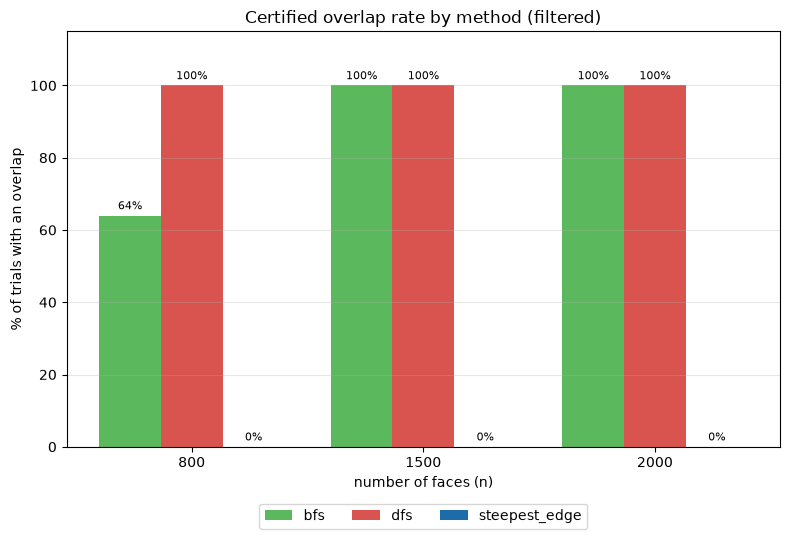

In [6]:
def plot_overlap_rate(summary_df, title, value_col):
    ns = sorted(summary_df["n_points"].unique())
    methods = sorted(summary_df["method"].unique())
    width = 0.8 / len(methods)

    fig, ax = plt.subplots(figsize=(8, 5.5))
    for i, method in enumerate(methods):
        sub = summary_df[summary_df["method"] == method].set_index("n_points")
        ys = [sub[value_col].get(n, 0.0) for n in ns]
        xs = [x + i * width for x in range(len(ns))]
        bars = ax.bar(xs, ys, width=width, label=method, color=METHOD_COLORS.get(method))
        for bar, y in zip(bars, ys):
            ax.text(bar.get_x() + bar.get_width() / 2, y + 1, f"{y:.0f}%", ha="center", va="bottom", fontsize=8)

    ax.set_xticks([x + width * (len(methods) - 1) / 2 for x in range(len(ns))])
    ax.set_xticklabels([str(n) for n in ns])
    ax.set_xlabel("number of faces (n)")
    ax.set_ylabel("% of trials with an overlap")
    ax.set_ylim(0, 115)
    ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=len(methods))
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

plot_overlap_rate(certified_summary, "Certified overlap rate by method (filtered)", "pct_trials_with_overlap")


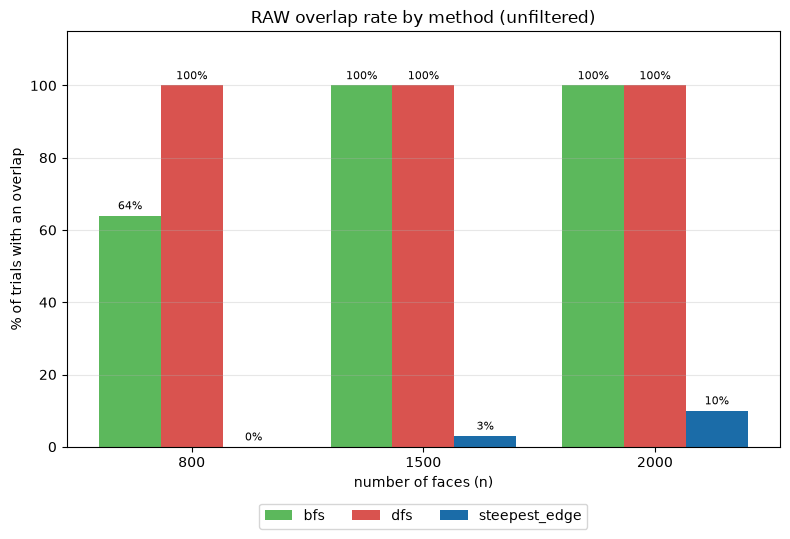

In [7]:
plot_overlap_rate(raw_summary, "RAW overlap rate by method (unfiltered)", "pct_trials_with_overlap")


## 5. steepest_edge: average inversive distance vs. face count

Zoomed in (the other methods are flat at ~1.0 or deeply negative, which
would hide steepest_edge's much finer trend on a shared axis).


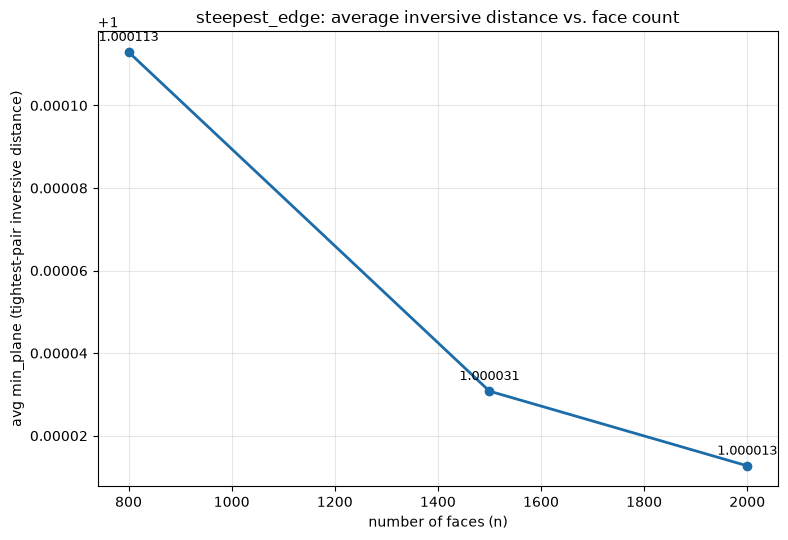

In [7]:
se = certified_summary[certified_summary["method"] == "steepest_edge"].sort_values("n_points")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(se["n_points"], se["avg_min_plane"], marker="o", color=METHOD_COLORS["steepest_edge"], linewidth=2)
for x, y in zip(se["n_points"], se["avg_min_plane"]):
    ax.annotate(f"{y:.6f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)

ax.set_xlabel("number of faces (n)")
ax.set_ylabel("avg min_plane (tightest-pair inversive distance)")
ax.set_title("steepest_edge: average inversive distance vs. face count")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


## 6. Bonus: margin decay (log-log) and all-methods comparison


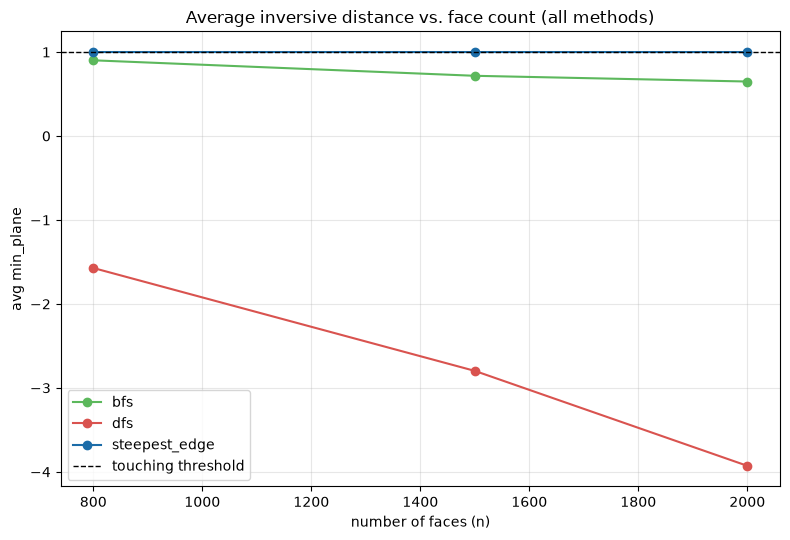

In [9]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for method in sorted(certified_summary["method"].unique()):
    sub = certified_summary[certified_summary["method"] == method].sort_values("n_points")
    ax.plot(sub["n_points"], sub["avg_min_plane"], marker="o", label=method, color=METHOD_COLORS.get(method))

ax.axhline(1.0, color="black", linestyle="--", linewidth=1, label="touching threshold")
ax.set_xlabel("number of faces (n)")
ax.set_ylabel("avg min_plane")
ax.set_title("Average inversive distance vs. face count (all methods)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


log-log slope for steepest_edge: -2.333  (audit's pre-fix measurement was -1.996)


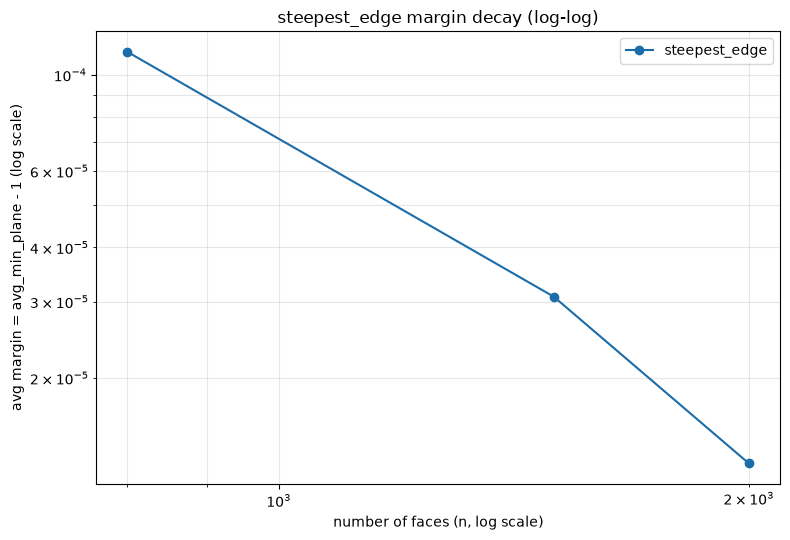

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))
se_pos = se[se["avg_min_plane"] > 1.0].copy()
se_pos["avg_margin"] = se_pos["avg_min_plane"] - 1.0
ax.plot(se_pos["n_points"], se_pos["avg_margin"], marker="o", color=METHOD_COLORS["steepest_edge"], label="steepest_edge")

if len(se_pos) >= 2:
    log_x = se_pos["n_points"].apply(math.log)
    log_y = se_pos["avg_margin"].apply(math.log)
    slope = ((log_x - log_x.mean()) * (log_y - log_y.mean())).sum() / ((log_x - log_x.mean()) ** 2).sum()
    print(f"log-log slope for steepest_edge: {slope:.3f}  (audit's pre-fix measurement was -1.996)")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("number of faces (n, log scale)")
ax.set_ylabel("avg margin = avg_min_plane - 1 (log scale)")
ax.set_title("steepest_edge margin decay (log-log)")
ax.legend()
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()


## Bottom line

- **Certified overlaps for steepest_edge across every n tested: 0.**
- The raw/unfiltered table above (section 3) is the ground truth if you
  don't trust the 10x certification cutoff -- inspect
  `ratio_deficit_to_residual` yourself; anything with `method ==
  "steepest_edge"` and a small ratio there is a borderline case worth a
  second look, e.g. by loading the corresponding `.pkl` files from
  `overlapping_packings/` (see `check_overlap_certification.py`).
